<a href="https://colab.research.google.com/github/someya2008/vibe/blob/main/genai_3d_lab_free.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧊 生成AIのしくみを「3D」で見る
### 写真1枚から立体を作る AI（Hunyuan3D-2）を、中をのぞきながら動かす

画像や 3D を作る生成AIの多くは、**「ノイズ（でたらめな数値）から出発して、少しずつ形を整える」**という同じ考え方で動いています。
このノートブックでは、その途中経過を **3D の形として目で見ながら** たどります。

| 章 | 分かること |
|---|---|
| 1・2 | AI は写真を「数値の特徴」として読む |
| 3 | 生成は「ノイズ」から始まる |
| 4 | 方向を予想して少しずつ進む ― 生成AIの心臓部 |
| 5 | 数値の場から立体の表面を取り出す |
| 6 | シード・ステップ数・ガイダンスで結果がどう変わるか（実験） |
| 7 | もう1つの生成AIで色を塗る（6方向の絵を描いて、展開図に貼る） |

**はじめる前に**
1. メニュー「ランタイム → ランタイムのタイプを変更」で **T4 GPU** を選ぶ（無料で使えます）
2. 上のセルから順に、左の ▶ を押していく（① と ② は合わせて 5〜8 分ほど。7 章の準備は裏で進みます）

<details><summary>このノートブックについて（利用条件・注意）</summary>

- 使う AI：Tencent 社の **Hunyuan3D-2**（形状生成モデル Hunyuan3D-DiT v2.0）。*Tencent Hunyuan 3D 2.0 Community License* に従います（EU・英国・韓国は許諾地域の対象外）。
- 見本画像は Hunyuan3D-2 のリポジトリに含まれる作例です。
- 自分の写真を使う場合、写真は Google のサーバー上の一時的な作業場所に置かれます。他人の作品や人物の写真は、権利と本人の同意を確認してから使いましょう。
- 7 章の色付けに必要な準備（約 10〜15 分）は、① のあと裏で自動的に進みます。無料版では本体メモリに余裕が少ないため、万一うまくいかないときも 1〜6 章はそのまま学べます。
- Hugging Face のアカウントやトークン（HF_TOKEN）は **不要** です。AI モデルは誰でもダウンロードできる公開モデルです。
</details>


## 0. 準備
2つのセルを順に実行します。① は道具をそろえるだけ、② は AI 本体を読み込みます。どちらも「✅ 準備完了」が出たら終わりです。


In [1]:
# @title ① 準備（最初に1回だけ・約3〜5分）
# @markdown ▶ を押して待つだけです。最後に「✅ 準備完了」と出たら次へ進みます。
# @markdown **7章「色を塗る」の準備**（ビルドとダウンロード、約10〜15分）を、1〜6章を進めている間に裏で行います。色付けをしないなら ✓ を外してください。
PREP_TEXTURE = True  # @param {type:"boolean"}
import os, re, subprocess, sys, time

REPO   = "/content/Hunyuan3D-2"
COMMIT = "f8db63096c8282cb27354314d896feba5ba6ff8a"   # 動作確認した版に固定
FONT_DIR = "/content/fonts"
PY = sys.executable
_t0 = time.time()
TEX_PREP_SCRIPT = '"""色付け（テクスチャ）の準備を裏で進めるスクリプト。① から自動で起動される。\n1) diffusers 新仕様への対応  2) C++ 拡張のビルド  3) CUDA 拡張のビルド  4) 色塗り AI のダウンロード\n進み具合は /content/tex_prep/status.txt、詳しい記録は log.txt、終わると done（失敗なら failed）を書く。"""\nimport os, subprocess, sys, time, traceback\n\nREPO = sys.argv[1] if len(sys.argv) > 1 else "/content/Hunyuan3D-2"\nARCH = sys.argv[2] if len(sys.argv) > 2 else ""\nST = sys.argv[3] if len(sys.argv) > 3 else "/content/tex_prep"\nPAINT = "hunyuan3d-paint-v2-0-turbo"\nos.makedirs(ST, exist_ok=True)\nfor f in ("done", "failed"):\n    if os.path.exists(os.path.join(ST, f)):\n        os.remove(os.path.join(ST, f))\nt0 = time.time()\n\n\ndef status(msg):\n    with open(os.path.join(ST, "status.txt"), "w", encoding="utf-8") as f:\n        f.write(msg)\n    print(f"[{time.time() - t0:5.0f}s] {msg}", flush=True)\n\n\ndef build(cwd, env=None):\n    r = subprocess.run([sys.executable, "setup.py", "build_ext", "--inplace"], cwd=cwd, env=env,\n                       text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)\n    print(r.stdout[-4000:], flush=True)\n    if r.returncode != 0:\n        tail = "\\n".join(l for l in r.stdout.splitlines() if "error" in l.lower())[-1500:]\n        raise RuntimeError(f"ビルドに失敗しました（{os.path.basename(cwd)}）\\n{tail}")\n\n\ntry:\n    with open(os.path.join(ST, "pid"), "w") as f:\n        f.write(str(os.getpid()))\n\n    status("1/4 diffusers の新しい仕様に合わせる")\n    mv = os.path.join(REPO, "hy3dgen/texgen/utils/multiview_utils.py")\n    src = open(mv, encoding="utf-8").read()\n    old = "custom_pipeline=custom_pipeline_path, torch_dtype=torch.float16)"\n    new = "custom_pipeline=custom_pipeline_path, torch_dtype=torch.float16, trust_remote_code=True)"\n    if new not in src:\n        assert src.count(old) == 1, "multiview_utils.py の想定した行が見つかりません"\n        open(mv, "w", encoding="utf-8").write(src.replace(old, new))\n\n    status("2/4 C++ 拡張をビルド中（1分ほど）")\n    build(os.path.join(REPO, "hy3dgen/texgen/differentiable_renderer"))\n\n    status("3/4 CUDA 拡張をビルド中（5〜10分）")\n    env = dict(os.environ, MAX_JOBS="2")\n    if ARCH:\n        env["TORCH_CUDA_ARCH_LIST"] = ARCH          # この GPU 用だけを作る（時間短縮）\n    build(os.path.join(REPO, "hy3dgen/texgen/custom_rasterizer"), env)\n\n    status("4/4 色塗り AI をダウンロード中（約 13 GB）")\n    from huggingface_hub import snapshot_download\n    snapshot_download("tencent/Hunyuan3D-2",\n                      allow_patterns=["hunyuan3d-delight-v2-0/*", f"{PAINT}/*"],\n                      ignore_patterns=[f"{PAINT}/unet/diffusion_pytorch_model.safetensors",   # 使われない重複ファイル\n                                       f"{PAINT}/image_encoder/*"])                          # 使われない部品\n    status(f"完了（{(time.time() - t0) / 60:.0f} 分）")\n    open(os.path.join(ST, "done"), "w").write("ok")\nexcept Exception as e:\n    traceback.print_exc()\n    status(f"失敗：{e}")\n    open(os.path.join(ST, "failed"), "w", encoding="utf-8").write(str(e))\n'   # 7章の準備用スクリプト（ノートブック作成時に中身を埋め込み）


def run(cmd, cwd=None):
    r = subprocess.run(cmd, shell=True, cwd=cwd, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    if r.returncode != 0:
        print(r.stdout[-3000:])
        raise RuntimeError(f"❌ 失敗しました: {cmd}")
    return r.stdout


print("🖥  GPU を確認中...")
out = run(f'{PY} -c "import torch; ok = torch.cuda.is_available(); '
          'cap = \'%d.%d\' % torch.cuda.get_device_capability(0) if ok else \'\'; '
          'print(\'PROBE\', ok, torch.cuda.get_device_name(0) if ok else \'-\', cap, sep=\'|\')"')
_, ok, gpu, cap = [l for l in out.splitlines() if l.startswith("PROBE|")][-1].split("|")
if ok != "True":
    raise RuntimeError("❌ GPU が使えません。メニュー「ランタイム → ランタイムのタイプを変更」で「T4 GPU」を選び、もう一度 ▶ を押してください。")
print(f"   {gpu}")

print("📥 AI のプログラムを取得中...")
if not os.path.isdir(os.path.join(REPO, "hy3dgen")):
    run(f"rm -rf {REPO} && git clone -q https://github.com/Tencent-Hunyuan/Hunyuan3D-2.git {REPO}")
    run(f"git -C {REPO} checkout -q {COMMIT}")

print("📦 必要なライブラリを入れています（ここが一番長くかかります）...")
run("apt-get -qq install -y libopengl0 > /dev/null 2>&1 || (apt-get -qq update && apt-get -qq install -y libopengl0 > /dev/null)")
# Colab に最初から入っている numpy の版を固定したまま入れる → ランタイムの再起動が不要になる
np_ver = run(f'{PY} -c "import numpy; print(numpy.__version__)"').strip().splitlines()[-1]
pkgs = [f"numpy=={np_ver}", "rembg==2.0.69", "onnxruntime", "pymeshlab", "trimesh",
        "einops", "pyyaml", "diffusers", "transformers", "accelerate",
        "xatlas", "pygltflib", "pybind11", "ninja"]          # 下の4つは7章（色付け）用
run(f"{PY} -m pip install -q " + " ".join(f'"{p}"' for p in pkgs))

print("🔤 図の日本語フォント（BIZ UDPゴシック）を準備中...")
os.makedirs(FONT_DIR, exist_ok=True)
for w in ("Regular", "Bold"):
    f = os.path.join(FONT_DIR, f"BIZUDPGothic-{w}.ttf")
    if not os.path.exists(f):
        run(f"curl -sSfL -o {f} https://raw.githubusercontent.com/google/fonts/main/ofl/bizudpgothic/BIZUDPGothic-{w}.ttf")

if PREP_TEXTURE:
    ST = "/content/tex_prep"
    os.makedirs(ST, exist_ok=True)
    with open("/content/tex_prep.py", "w", encoding="utf-8") as f:
        f.write(TEX_PREP_SCRIPT)
    running = False
    try:
        running = os.path.exists(f"{ST}/pid") and not os.path.exists(f"{ST}/done") and not os.path.exists(f"{ST}/failed") \
            and os.path.exists(f"/proc/{open(f'{ST}/pid').read().strip()}")
    except Exception:
        pass
    if os.path.exists(f"{ST}/done"):
        print("🎨 7章の準備はすでに完了しています。")
    elif running:
        print("🎨 7章の準備は裏で進行中です。")
    else:
        subprocess.Popen([PY, "/content/tex_prep.py", REPO, cap, ST], cwd="/content",
                         stdout=open(f"{ST}/log.txt", "w"), stderr=subprocess.STDOUT, start_new_session=True)
        print("🎨 7章（色を塗る）の準備を裏で開始しました（約10〜15分。進み具合は7章で確認できます）。")

print(f"\n✅ 準備完了（{time.time() - _t0:.0f} 秒）。次の ② に進んでください。")


🖥  GPU を確認中...
   Tesla T4
📥 AI のプログラムを取得中...
📦 必要なライブラリを入れています（ここが一番長くかかります）...
🔤 図の日本語フォント（BIZ UDPゴシック）を準備中...
🎨 7章（色を塗る）の準備を裏で開始しました（約10〜15分。進み具合は7章で確認できます）。

✅ 準備完了（40 秒）。次の ② に進んでください。


In [2]:
# @title ② AI モデルを読み込む（約2〜3分）
# @markdown 3D 形状を作る AI「Hunyuan3D-DiT v2.0」（約11億個の数値＝パラメータを持つモデル）を GPU に読み込みます。<br>
# @markdown このセルには、後の観察で使う「裏方の関数」も入っています（中身は読まなくて大丈夫）。
import os, sys, io, time, base64, contextlib, warnings
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # GPU メモリの断片化を減らす
import numpy as np
import torch
import trimesh
import matplotlib.pyplot as plt
from matplotlib import font_manager
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from PIL import Image
from IPython.display import display, HTML

warnings.filterwarnings("ignore")
REPO = "/content/Hunyuan3D-2"
if REPO not in sys.path:
    sys.path.insert(0, REPO)
OUT_DIR = "/content/outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# ── 図の見た目（日本語フォント・配色） ─────────────────────────────────
for f in ("BIZUDPGothic-Regular.ttf", "BIZUDPGothic-Bold.ttf"):
    p = os.path.join("/content/fonts", f)
    if os.path.exists(p):
        font_manager.fontManager.addfont(p)
plt.rcParams.update({"font.family": ["BIZ UDPGothic", "DejaVu Sans"], "font.size": 11,
                     "axes.titlesize": 12, "figure.facecolor": "white", "savefig.facecolor": "white"})
CLAY = np.array([0.84, 0.78, 0.71])          # 立体の色（素焼きの粘土のような色）
INK = "#2b2f38"

# ── transformers 5 への対応（DINOv2 の重みの名前を新しい名前に読み替える） ──────────
_RENAMES = [(".attention.attention.query.", ".attention.q_proj."),
            (".attention.attention.key.",   ".attention.k_proj."),
            (".attention.attention.value.", ".attention.v_proj."),
            (".attention.output.dense.",    ".attention.o_proj."),
            (".mlp.weights_out.",           ".mlp.down_proj.")]
if not hasattr(torch.nn.Module, "_orig_load_state_dict_hy3d"):
    torch.nn.Module._orig_load_state_dict_hy3d = torch.nn.Module.load_state_dict

def _patched_load_state_dict(self, state_dict, strict=True, assign=False):
    if any(".attention.attention.query." in k for k in state_dict) \
            and any(".attention.q_proj." in k for k in self.state_dict()):
        new_sd = {}
        for k, v in state_dict.items():
            for a, b in _RENAMES:
                k = k.replace(a, b)
            if ".mlp.weights_in." in k:
                gate, up = v.chunk(2, dim=0)
                new_sd[k.replace(".mlp.weights_in.", ".mlp.gate_proj.")] = gate
                new_sd[k.replace(".mlp.weights_in.", ".mlp.up_proj.")] = up
            else:
                new_sd[k] = v
        state_dict = new_sd
    return torch.nn.Module._orig_load_state_dict_hy3d(self, state_dict, strict=strict, assign=assign)

torch.nn.Module.load_state_dict = _patched_load_state_dict

from rembg import new_session, remove
from hy3dgen.shapegen import Hunyuan3DDiTFlowMatchingPipeline, FaceReducer, FloaterRemover, DegenerateFaceRemover
from hy3dgen.shapegen.pipelines import retrieve_timesteps

# ── モデルの読み込み ─────────────────────────────────────────────────────
# Hugging Face のトークン（HF_TOKEN）は不要：このモデルは誰でもダウンロードできる公開モデル。
# トークンを保存していない人には「HF_TOKEN がありません」という注意書きが出るが、無視してよいので非表示にする。
warnings.filterwarnings("ignore", message=r"(?s).*HF_TOKEN")

def _download_hint(e):
    msg = str(e)
    if "429" in msg or "Too Many Requests" in msg:
        return "ダウンロードの回数制限にかかりました。5 分ほど待ってから、もう一度 ▶ を押してください。"
    if "401" in msg or "403" in msg:
        return ("保存されている HF_TOKEN が無効（期限切れ・削除済みなど）の可能性があります。左の 🔑（シークレット）で"
                " HF_TOKEN を正しい値に直すか削除し、「ランタイム → セッションを再起動」してから ② をやり直してください。")
    return "ネットワークの一時的な不調の可能性があります。少し待って、もう一度 ▶ を押してください。"

def load_shape_pipeline(repo="tencent/Hunyuan3D-2", sub="hunyuan3d-dit-v2-0"):
    """形状生成 AI を読み込む。
    ・必要な2ファイルだけをダウンロード（フォルダ全体だと約 25 GB、必要なのは約 5 GB）
    ・部品を最初から GPU 上に作る → 本体メモリ（RAM）が 12 GB ほどの無料版でもあふれない"""
    from huggingface_hub import hf_hub_download
    cfg = hf_hub_download(repo, f"{sub}/config.yaml")
    ckpt = hf_hub_download(repo, f"{sub}/model.fp16.safetensors")
    with torch.device("cuda"):
        return Hunyuan3DDiTFlowMatchingPipeline.from_single_file(
            ckpt, cfg, device="cuda", dtype=torch.float16, use_safetensors=True,
            from_pretrained_kwargs=dict(model_path=repo, subfolder=sub, use_safetensors=True,
                                        variant="fp16", dtype=torch.float16, device="cuda"))

if "PIPE" not in globals():
    _t = time.time()
    print("⏳ モデルをダウンロードして GPU に読み込み中（初回は数分）...")
    try:
        PIPE = load_shape_pipeline()
    except Exception as e:
        raise RuntimeError("❌ モデルを読み込めませんでした。" + _download_hint(e)) from e
    REMBG = new_session(providers=["CPUExecutionProvider"])     # 背景除去は CPU で（GPU は 3D 生成に使う）
    print(f"   読み込み完了（{time.time() - _t:.0f} 秒）")
N_PARAMS = sum(p.numel() for p in PIPE.model.parameters())

# ── 見本画像（Hunyuan3D-2 リポジトリ同梱の作例。背景は透明） ─────────────────────
SAMPLES = {"椅子": "1679.png", "かぼちゃ": "1135.png", "機関車": "1022.png", "石像": "075.png",
           "雪だるま": "195.png", "タツノオトシゴ": "101.png", "クジラ": "example_002.png", "果物かご": "1601.png"}


def load_photo(path, remove_bg=True):
    img = Image.open(path)
    img = img.convert("RGBA")
    has_alpha = np.array(img)[:, :, 3].min() < 250
    if remove_bg and not has_alpha:
        img = remove(img, session=REMBG, bgcolor=[255, 255, 255, 0])
    return img


def on_white(img):
    return Image.alpha_composite(Image.new("RGBA", img.size, (255, 255, 255, 255)), img.convert("RGBA")).convert("RGB")


def tensor_to_pil(t):
    a = ((t[0].float().permute(1, 2, 0).cpu().numpy() + 1) / 2).clip(0, 1)
    return Image.fromarray((a * 255).astype(np.uint8))


@torch.inference_mode()
def encode(img):
    """写真 → AI が使う「条件」（DINOv2 の特徴）。写真なし版（全部 0）も一緒に作る"""
    cond_inputs = PIPE.prepare_image(img)
    image = cond_inputs.pop("image")
    cond = PIPE.encode_cond(image=image, additional_cond_inputs=cond_inputs,
                            do_classifier_free_guidance=True, dual_guidance=False)
    return image, cond_inputs.get("mask"), cond


# ── 3D の表示 ───────────────────────────────────────────────────────────
def _simplify(mesh, max_faces):
    if mesh is None or len(mesh.faces) <= max_faces:
        return mesh
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        return FaceReducer()(mesh.copy(), max_facenum=max_faces)


def draw_mesh(ax, mesh, max_faces=8000, elev=12, azim=-60):
    """メッシュを陰影つきで描く（生成物は Y が上・正面が +Z。図では Z を上にして表示）"""
    ax.set_axis_off()
    lim = 0.75
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    ax.set_box_aspect((1, 1, 1), zoom=1.3)
    ax.view_init(elev=elev, azim=azim)
    if mesh is None or len(mesh.faces) == 0:
        ax.text2D(0.5, 0.5, "まだ表面が\nできていない", transform=ax.transAxes, ha="center", va="center",
                  color="#9aa0aa", fontsize=12)
        return
    m = _simplify(mesh, max_faces)
    v = m.vertices.copy()
    v -= (v.max(0) + v.min(0)) / 2                       # 中央へ
    v = v / max(np.abs(v).max(), 1e-6) * 0.72            # 枠に収まる大きさへ
    v = np.stack([v[:, 0], -v[:, 2], v[:, 1]], 1)        # (x, y, z) → (x, -z, y)：Y 上 → Z 上
    tris = v[m.faces]
    vn = trimesh.Trimesh(v, m.faces, process=False).vertex_normals   # 頂点の向きを平均して、なめらかな陰影に
    n = vn[m.faces].mean(1)
    n /= np.linalg.norm(n, axis=1, keepdims=True) + 1e-12
    light = np.array([-0.35, -0.75, 0.55]); light /= np.linalg.norm(light)
    shade = 0.35 + 0.65 * np.abs(n @ light)             # 光の当たり方で明るさを変える（ランバート反射）
    colors = np.clip(CLAY[None] * shade[:, None], 0, 1)
    ax.add_collection3d(Poly3DCollection(tris, facecolors=colors, edgecolors=colors, linewidths=0.3))  # 面のすき間を埋める


def mesh_grid(items, cols=4, size=2.8, suptitle=None):
    """items = [(メッシュ or None, 見出し), ...] を並べて表示"""
    rows = (len(items) + cols - 1) // cols
    title_h, sup_h = 0.55, (0.55 if suptitle else 0.0)          # 見出し2行分・全体見出しの高さ（インチ）
    H = (size + title_h) * rows + sup_h
    fig = plt.figure(figsize=(size * cols, H))
    for k, (m, title) in enumerate(items):
        ax = fig.add_subplot(rows, cols, k + 1, projection="3d")
        draw_mesh(ax, m)
        ax.set_title(title, color=INK, pad=2, fontsize=11, linespacing=1.3)
    if suptitle:
        fig.suptitle(suptitle, fontsize=14, fontweight="bold", color=INK, y=1 - 0.1 / H, va="top")
    plt.subplots_adjust(left=0, right=1, bottom=0, top=1 - (sup_h + title_h) / H,
                        wspace=0.0, hspace=title_h / size)
    plt.show()


def has_texture(mesh):
    return getattr(getattr(mesh.visual, "material", None), "image", None) is not None \
        and getattr(mesh.visual, "uv", None) is not None


def matte_textured(mesh, max_px=None):
    """色の画像を貼った立体を、つや消し（金属でない）素材として書き出せる形にする"""
    m = mesh.copy()
    img = m.visual.material.image
    if max_px and max(img.size) > max_px:
        img = img.resize((max_px, max_px), Image.LANCZOS)
    m.visual = trimesh.visual.TextureVisuals(uv=m.visual.uv, material=trimesh.visual.material.PBRMaterial(
        baseColorTexture=img, metallicFactor=0.0, roughnessFactor=0.85))
    return m


def show_3d(mesh, height=440):
    """マウスで回せる 3D 表示（model-viewer）"""
    if has_texture(mesh):
        m = matte_textured(mesh, max_px=1024)            # 表示用に色の画像を軽くする
    else:
        m = _simplify(mesh, 60000).copy()
        m.visual = trimesh.visual.TextureVisuals(material=trimesh.visual.material.PBRMaterial(
            baseColorFactor=[214, 200, 182, 255], metallicFactor=0.0, roughnessFactor=0.8))
    b64 = base64.b64encode(m.export(file_type="glb", include_normals=True)).decode()
    display(HTML(f"""
<script type="module" src="https://cdn.jsdelivr.net/npm/@google/model-viewer@4.4.0/dist/model-viewer.min.js"></script>
<model-viewer src="data:model/gltf-binary;base64,{b64}" camera-controls auto-rotate rotation-per-second="20deg"
  shadow-intensity="1" exposure="1.05" environment-image="neutral" interaction-prompt="none"
  style="width:100%;height:{height}px;background:linear-gradient(#fafbfc,#e8ebf0);border-radius:14px"></model-viewer>
<div style="font:13px sans-serif;color:#666;margin-top:4px">ドラッグで回転・ホイール（2本指）で拡大縮小</div>"""))


# ── 潜在表現（形を表す数値）→ 立体 ────────────────────────────────────────
@torch.inference_mode()
def latents_to_mesh(lat, octree=112):
    """潜在表現 → 「各点が内側か外側か」の場 → マーチングキューブ法で表面を取り出す"""
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        out = PIPE._export(lat, output_type="trimesh", box_v=1.01, mc_level=0.0, num_chunks=8000,
                           octree_resolution=octree, mc_algo=None, enable_pbar=False)
    m = out[0]
    return m if (m is not None and len(m.faces) > 0) else None


@torch.inference_mode()
def field_slice(lat, res=180):
    """立体を正面から見て、ちょうど真ん中の断面で「内側／外側」の値を調べる"""
    dec = PIPE.vae(lat / PIPE.vae.scale_factor)
    g = np.linspace(-1.01, 1.01, res, dtype=np.float32)
    X, Y = np.meshgrid(g, g, indexing="xy")
    pts = np.stack([X, Y, np.zeros_like(X)], -1).reshape(1, -1, 3)
    q = torch.from_numpy(pts).to(PIPE.device, dtype=dec.dtype)
    val = torch.cat([PIPE.vae.geo_decoder(queries=q[:, i:i + 8000], latents=dec).float()
                     for i in range(0, q.shape[1], 8000)], 1).cpu().numpy().reshape(res, res)
    border = np.concatenate([val[0], val[-1], val[:, 0], val[:, -1]])
    if np.median(border) > 0:            # 外側（枠のあたり）がマイナスになるように向きをそろえる
        val = -val
    return val


def draw_slice(ax, val, title):
    lim = np.percentile(np.abs(val), 99) + 1e-6
    ax.imshow(val, cmap="RdBu_r", vmin=-lim, vmax=lim, origin="lower", extent=[-1, 1, -1, 1])
    if val.min() < 0 < val.max():
        ax.contour(val, levels=[0], colors=INK, linewidths=1.6, origin="lower", extent=[-1, 1, -1, 1])
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, color=INK)


# ── 各章の図を描く関数 ───────────────────────────────────────────────────
def show_photo(original, photo):
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.8))
    checker = (np.indices((32, 32)).sum(0) % 2 * 25 + 225).astype(np.uint8)
    bg = Image.fromarray(checker).resize(photo.size, Image.NEAREST).convert("RGBA")
    for ax, im, t in ((axes[0], on_white(original), "元の写真"),
                      (axes[1], Image.alpha_composite(bg, photo).convert("RGB"), "背景を消した写真（市松＝透明）")):
        ax.imshow(im); ax.set_title(t, color=INK); ax.axis("off")
    plt.tight_layout(); plt.show()


def show_features(image, mask, cond):
    enc = getattr(PIPE.conditioner, "main_image_encoder", None)
    feats = cond["main"][0].float().cpu().numpy()          # 1枚目＝写真あり（2枚目は写真なし＝全部 0）
    n_tok, dim = feats.shape
    if enc is not None and getattr(enc, "use_cls_token", False):
        feats = feats[1:]                                   # 先頭は「写真全体の要約」用の特別な1個
    side = int(round(np.sqrt(len(feats))))
    if side * side != len(feats):
        print(f"特徴の数 {n_tok} × {dim}（マス目の形にならないため色分け図は省略）"); return
    fg = np.ones(side * side, bool)
    if mask is not None:
        mk = (mask[0, 0].float().cpu().numpy() > 0).astype(np.float32)
        fg = np.array(Image.fromarray((mk * 255).astype(np.uint8)).resize((side, side), Image.BILINEAR)).reshape(-1) > 127
    if fg.sum() < 8:                                        # 物体のマスが少なすぎるときは全体で計算
        fg[:] = True
    X = feats[fg] - feats[fg].mean(0)
    _, _, vt = np.linalg.svd(X, full_matrices=False)       # 主成分分析（PCA）
    comp = (feats - feats[fg].mean(0)) @ vt[:3].T
    if comp.shape[1] < 3:
        comp = np.pad(comp, ((0, 0), (0, 3 - comp.shape[1])))
    lo, hi = np.percentile(comp[fg], 2, 0), np.percentile(comp[fg], 98, 0)
    rgb = np.clip((comp - lo) / (hi - lo + 1e-8), 0, 1)
    rgb[~fg] = 1.0
    rgb = rgb.reshape(side, side, 3)
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.9))
    axes[0].imshow(tensor_to_pil(image)); axes[0].set_title("AI に渡した画像", color=INK)
    axes[1].imshow(rgb, interpolation="nearest"); axes[1].set_title(f"AI が読み取った特徴（{side}×{side} マス）", color=INK)
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()
    print(f"写真は {side}×{side}＝{side * side} 個のマスに分けられ、各マスが {dim} 個の数値で表されています。")
    print(f"AI への「条件」は 合計 {n_tok} 個 × {dim} 個 ＝ {n_tok * dim:,} 個の数値です。")


def start_noise(seed):
    return PIPE.prepare_latents(1, PIPE.dtype, PIPE.device, torch.Generator("cpu").manual_seed(int(seed)))


def show_noise(noise):
    vals = noise.float().cpu().numpy().ravel()
    fig = plt.figure(figsize=(11, 3.6))
    ax1 = fig.add_subplot(1, 3, 1)
    ax1.hist(vals, bins=60, color="#7c8db5", edgecolor="white", linewidth=0.3)
    ax1.set_title("ノイズの数値の分布", color=INK); ax1.set_xlabel("値"); ax1.set_yticks([])
    for sp in ("top", "right", "left"): ax1.spines[sp].set_visible(False)
    draw_slice(fig.add_subplot(1, 3, 2), field_slice(noise), "ノイズの断面（赤＝内側／青＝外側）")
    ax3 = fig.add_subplot(1, 3, 3, projection="3d")
    draw_mesh(ax3, latents_to_mesh(noise)); ax3.set_title("ノイズをそのまま立体にすると", color=INK, pad=0)
    plt.tight_layout(); plt.show()
    shape = tuple(noise.shape[1:])
    print(f"潜在表現の大きさ：{shape[0]} 行 × {shape[1]} 列 ＝ {np.prod(shape):,} 個の数値（平均 {vals.mean():+.3f}、ばらつき {vals.std():.3f}）")


def clean_mesh(mesh):
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        mesh = FloaterRemover()(mesh)          # 本体から離れた小さなかけらを除く
        mesh = DegenerateFaceRemover()(mesh)   # 面積ゼロなどの壊れた三角形を除く
    return mesh


def show_field_and_mesh(noise, latent, mesh):
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.9))
    draw_slice(axes[0], field_slice(noise), "出発点（ノイズ）の断面")
    draw_slice(axes[1], field_slice(latent), "完成時の断面（黒線＝表面）")
    plt.tight_layout(); plt.show()


def save_outputs(mesh, name="my_model"):
    glb = os.path.join(OUT_DIR, f"{name}.glb"); stl = os.path.join(OUT_DIR, f"{name}.stl")
    m = mesh.copy()
    m.visual = trimesh.visual.TextureVisuals(material=trimesh.visual.material.PBRMaterial(
        baseColorFactor=[214, 200, 182, 255], metallicFactor=0.0, roughnessFactor=0.8))
    m.export(glb)
    p = mesh.copy()                                       # 3D プリント用：Z を上に、最長辺 80 mm、底面を高さ 0 に
    p.apply_transform(trimesh.transformations.rotation_matrix(np.pi / 2, [1, 0, 0]))
    p.apply_scale(80.0 / p.extents.max())
    (x0, y0, z0), (x1, y1, z1) = p.bounds
    p.apply_translation([-(x0 + x1) / 2, -(y0 + y1) / 2, -z0])
    p.export(stl)
    return glb, stl


def experiment(cond, settings, octree=128, title=None):
    """settings = [(見出し, ステップ数, ガイダンス, シード), ...] を順に生成して並べる"""
    if "denoise" not in globals():
        raise RuntimeError("先に「4. ノイズから形へ」のセルを実行してください。")
    items = []
    for label, steps, guidance, seed in settings:
        t = time.time()
        lat, _ = denoise(cond, steps=steps, guidance=guidance, seed=seed)
        m = latents_to_mesh(lat, octree=octree)
        if m is not None:
            m = clean_mesh(m)
        items.append((m, f"{label}\n（{time.time() - t:.0f} 秒）"))
        print(f"  ✓ {label.replace(chr(10), ' ')}")
    mesh_grid(items, cols=len(items), size=2.9, suptitle=title)


print(f"✅ 準備完了：形状生成 AI のパラメータ数 ＝ 約 {N_PARAMS / 1e8:.0f} 億個（{N_PARAMS:,} 個）")
print(f"   GPU：{torch.cuda.get_device_name(0)}")


⏳ モデルをダウンロードして GPU に読み込み中（初回は数分）...


config.yaml:   0%|          | 0.00/1.60k [00:00<?, ?B/s]

hunyuan3d-dit-v2-0/model.fp16.safetensor(…): reconstructing file:   0%|          |  0.00B / 4.93GB            

hunyuan3d-dit-v2-0/model.fp16.safetensor(…): downloading bytes:           |  0.00B            

2026-10-29 05:11:50,155 - hy3dgen.shapgen - INFO - Loading model from /root/.cache/huggingface/hub/models--tencent--Hunyuan3D-2/snapshots/9cd649ba6913f7a852e3286bad86bfa9a2d83dcf/hunyuan3d-dit-v2-0/model.fp16.safetensors
INFO:hy3dgen.shapgen:Loading model from /root/.cache/huggingface/hub/models--tencent--Hunyuan3D-2/snapshots/9cd649ba6913f7a852e3286bad86bfa9a2d83dcf/hunyuan3d-dit-v2-0/model.fp16.safetensors


PointCrossAttentionEncoder INFO: pc_sharpedge_size is given, using pc_size=5120, pc_sharpedge_size=5120


  0%|                                               | 0.00/176M [00:00<?, ?B/s]

   読み込み完了（64 秒）
✅ 準備完了：形状生成 AI のパラメータ数 ＝ 約 11 億個（1,113,274,432 個）
   GPU：Tesla T4


## 1. 写真を用意する
文章から絵を描く AI では「プロンプト（指示文）」で何を作るかを伝えますが、この AI では **写真が指示（＝条件）** になります。

- 見本から選ぶか、自分の写真を使います。**1つの物体が真ん中に大きく写った写真**が向いています。
- 背景は自動で消します。AI に「この物体だけを見てほしい」からです。


In [ ]:
# @title 写真を選ぶ
# @markdown 見本から選ぶか、「自分の写真を使う」に ✓ を入れて ▶（アップロード画面が出ます）
SAMPLE = "椅子"  # @param ["椅子", "かぼちゃ", "機関車", "石像", "雪だるま", "タツノオトシゴ", "クジラ", "果物かご"]
USE_MY_PHOTO = True  # @param {type:"boolean"}

if USE_MY_PHOTO:
    from google.colab import files
    uploaded = files.upload()
    name, data = next(iter(uploaded.items()))
    PHOTO_PATH = os.path.join(OUT_DIR, name)
    with open(PHOTO_PATH, "wb") as f:
        f.write(data)
else:
    PHOTO_PATH = os.path.join(REPO, "assets/example_images", SAMPLES[SAMPLE])

ORIGINAL = Image.open(PHOTO_PATH).convert("RGBA")
PHOTO = load_photo(PHOTO_PATH)          # 背景を消す（すでに透明なら何もしない）
show_photo(ORIGINAL, PHOTO)


## 2. AI の「目」に写ったもの
AI は写真を絵として眺めているわけではありません。まず **DINOv2** という「画像を理解する AI」が、写真を数値に置き換えます。

1. 写真を小さなマス目に分ける
2. 1つ1つのマスを **1000 個を超える数値の並び（特徴ベクトル）** で表す ― 色だけでなく「脚っぽい」「取っ手っぽい」といった意味も数値に込められます

それだけ多くの数値は図にできないので、**主成分分析（PCA）** で「マスどうしの違いがいちばん大きく出る3つの方向」だけを取り出し、赤・緑・青に割り当てて塗ります。
**同じような色のマス ＝ AI が「似ている」と感じている部分** です。

<details><summary>もう少し詳しく</summary>

- DINOv2（Meta 社、2023年）は、正解ラベルなしで大量の画像から学ぶ「自己教師あり学習」で作られた画像認識 AI です。物の部位ごとにまとまった特徴を出すことが知られています。
- 3D を作る AI 本体は、この数値の並びを **「条件」** として受け取り、形を作る間ずっと参照します（クロスアテンションという仕組み）。
- 写真なし版（すべて 0 の並び）も同時に作っておきます。4 章の「ガイダンス」で使います。
</details>


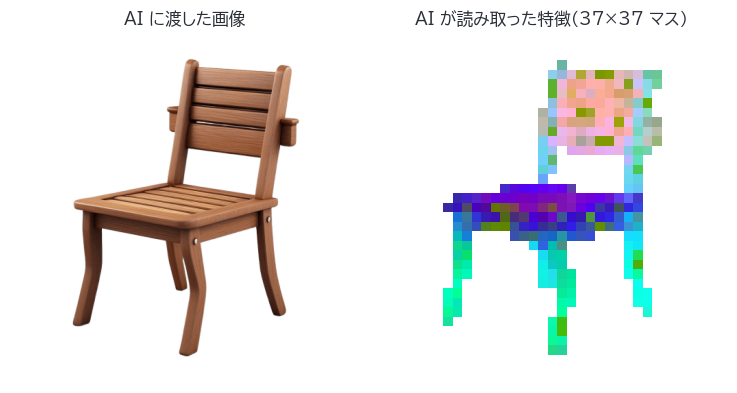

写真は 37×37＝1369 個のマスに分けられ、各マスが 1536 個の数値で表されています。
AI への「条件」は 合計 1370 個 × 1536 個 ＝ 2,104,320 個の数値です。


In [4]:
# 写真 → AI が使う「条件」（数値の並び）に変換し、その中身を色分けして見る
IMAGE, MASK, COND = encode(PHOTO)
show_features(IMAGE, MASK, COND)


## 3. 出発点は「ノイズ」
この AI は、形を点や三角形で直接扱うのではなく、**潜在表現**（形をぎゅっと圧縮して表した数値の表）の上で考えます。
生成は、この表を **でたらめな乱数（ノイズ）** で埋めるところから始まります。

- 乱数は「平均 0・ばらつき 1」の **正規分布**（つりがね型の分布）から選びます（下の左図）。
- 乱数の出方を決める番号が **シード値**。同じシードなら毎回まったく同じノイズになります。
- 右の2つの図は、ノイズを無理やり立体に戻そうとしたものです。まだ「形」と呼べるものはありません。


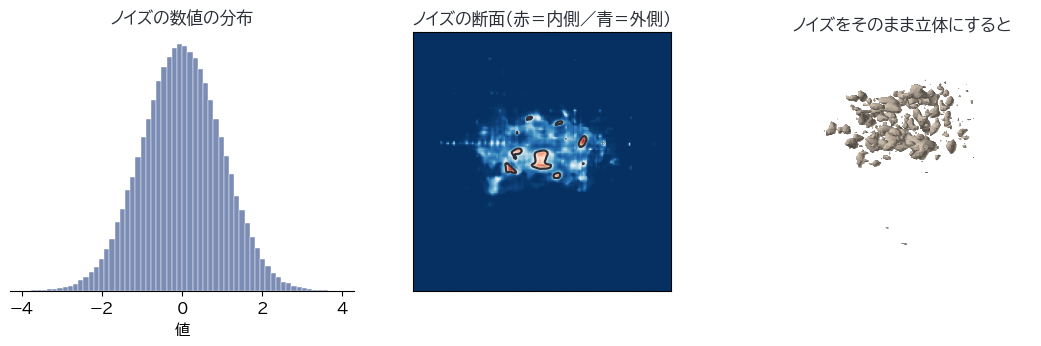

潜在表現の大きさ：3072 行 × 64 列 ＝ 196,608 個の数値（平均 -0.001、ばらつき 1.000）


In [5]:
# @title ノイズを作る
SEED = 42  # @param {type:"integer"}
NOISE = start_noise(SEED)      # 乱数で潜在表現を埋める
show_noise(NOISE)


## 4. ノイズから形へ ― 生成AIの心臓部
ここがいちばん大事なところです。AI は次の手順を何十回もくり返します。

1. いまの状態 **x** と写真の特徴を見て、「完成形へ向かう方向」**v** を予想する（この予想をするのが約11億個の数値＝パラメータをもつネットワーク）
2. その方向へ **少しだけ** 進む：　**x ← x + Δσ × v**
   σ（シグマ）は進み具合を表す数で、**0＝完全なノイズ、1＝完成**。Δσ は1回あたりの進み幅です。
3. σ が 1 になるまでくり返す

途中で「このまま一気に完成まで進んだら？」と計算すると、AI がその時点で思い描いている完成形（**予想図**）が見えます：　**予想図 ＝ x + (1 − σ) × v**

下のセルのコードが、その手順そのものです（①〜④のコメントに対応）。

<details><summary>③「写真に従う強さ（ガイダンス）」のしくみ</summary>

各ステップで方向を2回予想します。写真ありの予想 **v<sub>写真</sub>** と、写真なし（特徴をすべて 0）の予想 **v<sub>なし</sub>** です。それを

**v ＝ v<sub>なし</sub> ＋ s ×（v<sub>写真</sub> − v<sub>なし</sub>）**

と混ぜます。s がガイダンスの値です。
- s ＝ 1：写真ありの予想そのもの
- s ＞ 1：「写真があることで変わる部分」を強調する → 写真に似やすいが、上げすぎると形が荒れる
- s ＝ 0：写真を無視して作る

この方法は Classifier-Free Guidance（Ho & Salimans, 2022）と呼ばれ、画像生成 AI でも広く使われています。
</details>

<details><summary>「拡散モデル」と「フローマッチング」</summary>

画像生成でよく聞く「拡散モデル」は、ノイズを少しずつ取り除く練習をした AI です。この AI は、その仲間の **フローマッチング**（Lipman ほか, 2023）という方式で学習しています。

学習では、本物の形 x<sub>形</sub> とノイズ x<sub>ノイズ</sub> を σ の割合で混ぜたもの
**x ＝ (1 − σ) × x<sub>ノイズ</sub> ＋ σ × x<sub>形</sub>**
を見せて、「ノイズから形へ向かう方向」**v ＝ x<sub>形</sub> − x<sub>ノイズ</sub>** を当てる練習をくり返します。
この式を変形すると x<sub>形</sub> ＝ x ＋ (1 − σ) × v となり、これが「予想図」の式の根拠です。
</details>


生成：39.5 秒（30 ステップ）。予想図を立体にして並べています…


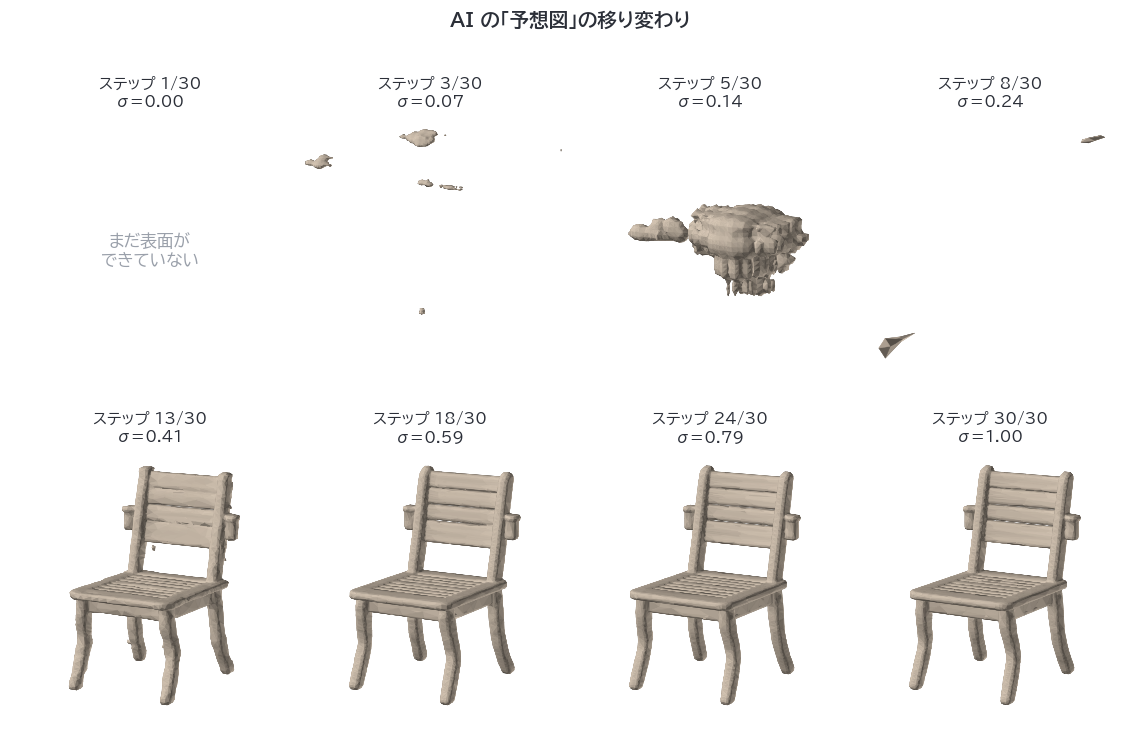

In [6]:
# @title ▶ ノイズから形を作る（T4 で 1〜2 分が目安）
STEPS = 30  # @param {type:"slider", min:2, max:50, step:1}
GUIDANCE = 5.0  # @param {type:"slider", min:0, max:10, step:0.5}

@torch.inference_mode()
def denoise(cond, steps=30, guidance=5.0, seed=42, keep=()):
    x = start_noise(seed)                                                  # ① ノイズから出発
    timesteps, _ = retrieve_timesteps(PIPE.scheduler, steps, PIPE.device,
                                      sigmas=np.linspace(0, 1, steps))     #    σ を 0 → 1 に刻む
    previews = {}
    for i, t in enumerate(timesteps):
        sigma = float(PIPE.scheduler.sigmas[i])                            #    進み具合（0＝ノイズ … 1＝完成）
        tt = t.expand(2).to(x.dtype) / PIPE.scheduler.config.num_train_timesteps
        v_photo, v_blind = PIPE.model(torch.cat([x, x]), tt, cond).chunk(2)  # ② 写真あり／なしで「方向」を予想
        v = v_blind + guidance * (v_photo - v_blind)                       # ③ 写真に従う強さで混ぜる
        if i in keep:
            previews[i] = (sigma, x + (1 - sigma) * v)                     #    （観察用）いまの予想図
        x = PIPE.scheduler.step(v, t, x).prev_sample                       # ④ 少しだけ進む：x ← x + Δσ × v
    return x, previews


keep = sorted({round(f * (STEPS - 1)) for f in (0, 0.07, 0.15, 0.25, 0.4, 0.6, 0.8, 1.0)})
_t = time.time()
LATENT, PREVIEWS = denoise(COND, STEPS, GUIDANCE, SEED, keep)
print(f"生成：{time.time() - _t:.1f} 秒（{STEPS} ステップ）。予想図を立体にして並べています…")
mesh_grid([(latents_to_mesh(lat), f"ステップ {i + 1}/{STEPS}\nσ＝{s:.2f}") for i, (s, lat) in PREVIEWS.items()],
          cols=4, suptitle="AI の「予想図」の移り変わり")


## 5. 数値の場から立体へ
くり返しが終わっても、x はまだ数値の表です。これを立体にするのが **VAE のデコーダ** という部品で、空間のどの点についても「物体の **内側か外側か**」を表す値を返します。

- 下の図は、立体を正面から見て **ちょうど真ん中で切った断面** の値です（赤＝内側、青＝外側）。値が 0 になる境目（黒い線）が表面です。
- 空間を方眼に区切り、すべてのマス目でこの値を調べて、0 になる境目を小さな三角形でつないでいくと立体の表面ができます。これを **マーチングキューブ法** といいます（1987 年に発表され、CT や MRI の画像を立体にするのにも使われています）。


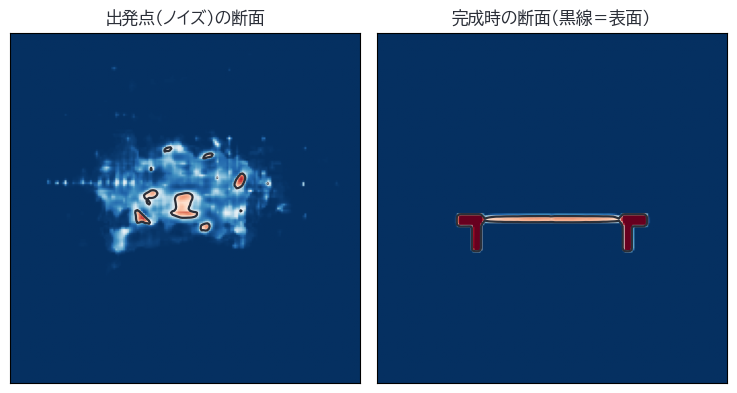

三角形の面：292,698 枚　／　頂点：146,327 個


In [7]:
# @title ▶ 立体に仕上げる（数十秒）
FINAL = latents_to_mesh(LATENT, octree=256)     # 空間を一辺 256 マスの方眼に区切って表面を取り出す
if FINAL is None:
    print("表面ができませんでした。4 章でシード値やステップ数を変えてやり直してください。")
else:
    FINAL = clean_mesh(FINAL)                   # 浮いた小さなかけらなどを掃除
    show_field_and_mesh(NOISE, LATENT, FINAL)
    print(f"三角形の面：{len(FINAL.faces):,} 枚　／　頂点：{len(FINAL.vertices):,} 個")
    show_3d(FINAL)
    GLB_PATH, STL_PATH = save_outputs(FINAL)


In [8]:
# @title ファイルをダウンロード（任意）
# @markdown GLB＝Web 表示・AR 用　／　STL＝3D プリント用（Z 軸が上・最長辺 80 mm・底面が高さ 0）
WHICH = "GLB と STL"  # @param ["GLB と STL", "GLB だけ", "STL だけ"]
from google.colab import files
if "GLB" in WHICH:
    files.download(GLB_PATH)
if "STL" in WHICH:
    files.download(STL_PATH)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. 実験してみよう
1つだけ条件を変えて、結果を並べて比べます（どれも T4 で数分が目安。かかった時間は図に表示されます）。結果を見る前に、どうなるか予想してみましょう。


### 実験1：シード値だけを変える
写真も設定も同じで、出発点のノイズだけを変えます。

**考えてみよう**：同じ指示なのに形が変わるのはなぜ？　写真に写っていない「裏側」は、どうやって決まっている？


In [ ]:
# @title ▶ 実験1
SEEDS = "1, 2, 3, 4"  # @param {type:"string"}
experiment(COND, [(f"シード {s}", 30, 5.0, s) for s in map(int, SEEDS.split(","))],
           title="同じ写真・同じ設定で、乱数の種（シード）だけを変えると…")


### 実験2：ステップ数（くり返しの回数）を変える
**考えてみよう**：回数が少ないと何が起きる？　回数を増やし続ければ、ずっと良くなる？

<details><summary>ヒント</summary>2 ステップの場合、σ は 0 と 1 の2つだけなので、実質「ノイズから1回の予想で一気に完成させる」ことになります。</details>


In [ ]:
# @title ▶ 実験2
STEP_LIST = "2, 5, 10, 30"  # @param {type:"string"}
experiment(COND, [(f"{n} ステップ", n, 5.0, SEED) for n in map(int, STEP_LIST.split(","))],
           title="くり返しの回数（ステップ数）を変えると…")


### 実験3：ガイダンス（写真に従う強さ）を変える
**考えてみよう**：ガイダンス 0（写真を無視）で出てくる形は、何を表している？　強くしすぎると何が起きる？


In [ ]:
# @title ▶ 実験3
GUIDANCE_LIST = "0, 1, 3, 8"  # @param {type:"string"}
experiment(COND, [(f"ガイダンス {g:g}", 30, g, SEED) for g in map(float, GUIDANCE_LIST.split(","))],
           title="写真に従う強さ（ガイダンス）を変えると…")


## 7. 色を塗る（テクスチャ・マッピング）
形を作った AI とは別の、**色を塗る生成 AI**（Hunyuan3D-Paint）を使います。ここでも中心にあるのは、4 章と同じ「ノイズから少しずつ絵を整える」しくみです。

1. **写真から光と影を取り除く** ― 写真の影や照り返しが、そのまま「色」として塗られないように
2. **表面を切り開いて平らな展開図（UV マップ）を作る** ― 服の型紙のように、立体の表面を平面に広げる
3. **6 方向から見た「面の向き」と「位置」の地図を作る** ― AI に立体の形を伝える手がかり
4. **6 方向から見た絵を、AI が同時に描く** ― 1 枚ずつではなく同時に描くので、方向ごとの絵が食い違いにくい
5. **6 枚の絵を展開図に貼り付ける（ベイク）** ― 正面の絵ほど、またカメラに正対している面ほど重く混ぜる
6. **どのカメラからも見えなかった所を、周りの色で埋める（インペイント）**

① の時点で、必要なプログラムの組み立て（ビルド）とダウンロードを裏で始めています。終わっていなければ、下のセルが終わるまで待ちます。

<details><summary>無料版で動かすための工夫</summary>

- 色塗り AI は、絵を描く部品だけで約 7 GB のファイルがあります。そのまま読むと本体メモリ（約 12 GB）があふれるため、ファイルを少しずつ読む方法（mmap）と、作った直後に半精度（16 ビット）にする方法で、使うメモリを半分以下に抑えています。
- GPU に余裕があれば、形を作る AI も GPU に載せたまま塗ります（いちばん速く、本体メモリも使わない）。足りなかった場合だけ、形の AI をいったん本体メモリへ退避させて塗り直します。GPU が足りないときはエラーとして検出して安全にやり直せますが、本体メモリがあふれると実行環境ごと止まってしまうので、本体メモリを使う方を「最後の手段」にしています。
- 少ない手順で描けるように追加学習した **Turbo 版**（10 ステップ）を使っています。
</details>


In [ ]:
# @title 色塗り AI を準備する（①で裏で進めていた準備の完了を待ってから読み込みます）
import gc, contextlib, subprocess
ST = "/content/tex_prep"


def _prep_status():
    try:
        return open(f"{ST}/status.txt", encoding="utf-8").read().strip()
    except Exception:
        return "（まだ記録がありません）"


def _prep_running():
    try:
        return os.path.exists(f"/proc/{open(f'{ST}/pid').read().strip()}")
    except Exception:
        return False


if "TEX" not in globals():
    # ── ① の裏の準備が終わるまで待つ（動いていなければ、ここで始める） ──
    if not os.path.exists(f"{ST}/done") and not _prep_running():
        if os.path.exists("/content/tex_prep.py") and not os.path.exists(f"{ST}/failed"):
            print("裏の準備が動いていなかったので、ここで始めます（約10〜15分）。")
            cap = "%d.%d" % torch.cuda.get_device_capability(0)
            subprocess.Popen([sys.executable, "/content/tex_prep.py", REPO, cap, ST], cwd="/content",
                             stdout=open(f"{ST}/log.txt", "w"), stderr=subprocess.STDOUT, start_new_session=True)
            time.sleep(3)
        elif not os.path.exists("/content/tex_prep.py"):
            raise RuntimeError("① を「7章の準備」に ✓ を入れて実行し直してください（入れたまま実行すると、ここから続けられます）。")
    last, _t = "", time.time()
    while not os.path.exists(f"{ST}/done") and not os.path.exists(f"{ST}/failed"):
        s = _prep_status()
        if s != last:
            print(f"  … {s}（待ち時間 {time.time() - _t:.0f} 秒）"); last = s
        if not _prep_running() and not os.path.exists(f"{ST}/done"):
            time.sleep(2)
            if not os.path.exists(f"{ST}/done") and not os.path.exists(f"{ST}/failed"):
                raise RuntimeError("準備の処理が途中で止まりました。① をもう一度実行してください。")
        time.sleep(5)
    if os.path.exists(f"{ST}/failed"):
        print(open(f"{ST}/failed", encoding="utf-8").read())
        raise RuntimeError("❌ この実行環境では色付けの準備ができませんでした（上の理由を参照）。1〜6章はそのまま使えます。")
    print("  ✓ ビルドとダウンロードが完了")

    # ── 読み込み：本体メモリ（RAM）があふれないための工夫 ──
    @contextlib.contextmanager
    def ram_saving_patches():
        """色塗り AI の大きな部品（約 7 GB のファイル）を読むときに、
        ・ファイルを丸ごとメモリに読まず、必要な部分だけ読む（mmap）
        ・部品を作った直後に半精度（16ビット）にして、大きさを半分にする"""
        import diffusers, diffusers.models as dm
        _ = diffusers.UNet2DConditionModel            # 他の部品には影響させない
        orig_unet, orig_load = dm.UNet2DConditionModel, torch.load
        class UNetHalf(orig_unet):
            def __init__(self, *a, **k):
                super().__init__(*a, **k)
                self.half()
        def load_mmap(*a, **k):
            k.setdefault("mmap", True)
            try:
                return orig_load(*a, **k)
            except Exception:
                k.pop("mmap", None)
                return orig_load(*a, **k)
        dm.UNet2DConditionModel, torch.load = UNetHalf, load_mmap
        try:
            yield
        finally:
            dm.UNet2DConditionModel, torch.load = orig_unet, orig_load

    CR_DIR = os.path.join(REPO, "hy3dgen/texgen/custom_rasterizer")
    if CR_DIR not in sys.path:
        sys.path.insert(0, CR_DIR)                    # ビルドした CUDA 拡張を読めるようにする
    import custom_rasterizer  # noqa: F401
    from huggingface_hub import snapshot_download
    from hy3dgen.texgen.pipelines import Hunyuan3DPaintPipeline, Hunyuan3DTexGenConfig
    from hy3dgen.texgen.utils.uv_warp_utils import mesh_uv_wrap
    PAINT = "hunyuan3d-paint-v2-0-turbo"
    root = snapshot_download("tencent/Hunyuan3D-2", allow_patterns=["hunyuan3d-delight-v2-0/*", f"{PAINT}/*"],
                             ignore_patterns=[f"{PAINT}/unet/diffusion_pytorch_model.safetensors", f"{PAINT}/image_encoder/*"])
    print("⏳ 色塗り AI を GPU に読み込み中（1〜2分）...")
    _t = time.time()
    with ram_saving_patches():
        TEX = Hunyuan3DPaintPipeline(Hunyuan3DTexGenConfig(
            os.path.join(root, "hunyuan3d-delight-v2-0"), os.path.join(root, PAINT), PAINT))
    gc.collect(); torch.cuda.empty_cache()
    print(f"✅ 準備完了（{time.time() - _t:.0f} 秒）。GPU 使用量 {torch.cuda.memory_allocated() / 1024**3:.1f} GB"
          f" ／ 全 {torch.cuda.get_device_properties(0).total_memory / 1024**3:.0f} GB")


# ── 色塗りの途中経過を見せる図 ───────────────────────────────────────────
VIEW_NAMES = ["正面", "横（90°）", "背面", "横（270°）", "真上", "真下"]


def _thumb(im, size=256):
    im = im if isinstance(im, Image.Image) else Image.fromarray(im)
    return im.convert("RGB").resize((size, size), Image.LANCZOS)


def show_row(images, titles, suptitle):
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(2.3 * n, 2.9))
    for ax, im, t in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(_thumb(im)); ax.set_title(t, color=INK); ax.axis("off")
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", color=INK, y=0.98)
    plt.tight_layout(); plt.show()


def show_paint_steps(info):
    show_row([on_white(info["photo"]), info["lit_free"]], ["写真", "光と影を取り除いた写真"], "① 光と影を取り除く")
    show_row(info["normals"], VIEW_NAMES, "③ AI に渡す「面の向き」の地図（色＝面の向き）")
    show_row(info["views"], VIEW_NAMES, "④ AI が描いた 6 方向の絵")
    tex = info["texture"]
    fig, axes = plt.subplots(1, 2, figsize=(8.4, 4.4))
    axes[0].imshow(_thumb(tex, 512)); axes[0].set_title("⑤⑥ 展開図（UV マップ）に塗られた色", color=INK)
    axes[1].imshow(info["mask"], cmap="gray"); axes[1].set_title("どこかのカメラから見えた部分（白）", color=INK)
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()
    print("右の図：白＝どれかのカメラから見えて色が決まった部分、黒＝見えなかった部分や展開図のすき間。"
          "見えなかった部分は、周りの色で埋めています（⑥）。")


def camera_ids(elevs, azims):
    """方向（仰角・方位角）を、AI が学習したときに使った「カメラ番号」に変換する（Hunyuan3D-2 の決まり）"""
    return [(((a // 30) + 9) % 12) // {-20: 1, 0: 1, 20: 1, -90: 3, 90: 3}[e]
            + {-20: 0, 0: 12, 20: 24, -90: 36, 90: 40}[e] for a, e in zip(azims, elevs)]


def is_oom(e):
    """GPU メモリ不足のエラーかどうか"""
    return isinstance(e, torch.cuda.OutOfMemoryError) or "out of memory" in str(e).lower()


def _bytes_on_gpu(modules):
    seen, total = set(), 0
    for mod in modules:
        if not isinstance(mod, torch.nn.Module):
            continue
        for t in list(mod.parameters()) + list(mod.buffers()):
            if t.is_cuda and t.data_ptr() not in seen:
                seen.add(t.data_ptr()); total += t.numel() * t.element_size()
    return total


def show_gpu_budget(title):
    """GPU メモリの使いみちを帯グラフで見せる"""
    free, total = torch.cuda.mem_get_info()
    shape = _bytes_on_gpu([PIPE.model, PIPE.vae, PIPE.conditioner])
    tex_mods = []
    for key in ("delight_model", "multiview_model"):
        pipe = getattr(TEX.models.get(key), "pipeline", None)
        if pipe is not None:
            tex_mods += list(pipe.components.values())
    paint_b = _bytes_on_gpu(tex_mods)
    other = max(total - free - shape - paint_b, 0)
    G = 1024**3
    parts = [("形の AI", shape, "#8fa3c8"), ("色の AI", paint_b, "#d9a46c"), ("作業用・その他", other, "#c9ccd3"), ("空き", free, "#eef0f3")]
    fig, ax = plt.subplots(figsize=(10, 1.5))
    x = 0
    for name, b, col in parts:
        ax.barh(0, b / G, left=x, color=col, edgecolor="white", height=0.6)
        if b / G > 0.9:
            ax.text(x + b / G / 2, 0, f"{name}\n{b / G:.1f} GB", ha="center", va="center", fontsize=10, color=INK)
        x += b / G
    ax.set_xlim(0, total / G); ax.set_yticks([]); ax.set_xlabel("GB")
    for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
    ax.set_title(f"{title}（全 {total / G:.1f} GB）", color=INK, loc="left")
    plt.tight_layout(); plt.show()


In [ ]:
# @title ▶ 色を塗る（T4 で 3〜6 分が目安）
@torch.no_grad()
def paint(mesh, photo, max_faces=40000):
    T = TEX
    m = _simplify(mesh, max_faces)                                       #    面を減らして展開図づくりを速くする
    m = m.copy() if m is mesh else m
    img = T.recenter_image(photo)                                        #    写真の余白を整える
    lit_free = T.models["delight_model"](img)                            # ① 写真から光と影を取り除く
    m = mesh_uv_wrap(m)                                                  # ② 表面を切り開いて展開図（UV）を作る
    T.render.load_mesh(m)
    elevs, azims = T.config.candidate_camera_elevs, T.config.candidate_camera_azims   # 6 方向（4 方位＋真上・真下）
    normals = T.render_normal_multiview(elevs, azims, use_abs_coor=True) # ③ 6 方向から見た「面の向き」の地図
    positions = T.render_position_multiview(elevs, azims)                #    6 方向から見た「位置」の地図
    views = T.models["multiview_model"]([lit_free], normals + positions, camera_ids(elevs, azims))  # ④ 6 方向の絵を同時に描く
    views = [v.resize((T.config.render_size,) * 2) for v in views]
    texture, seen = T.bake_from_multiview(views, elevs, azims, T.config.candidate_view_weights,
                                          method=T.config.merge_method)  # ⑤ 6 枚の絵を展開図に貼り付ける
    seen = (seen.squeeze(-1).cpu().numpy() * 255).astype(np.uint8)
    texture = T.texture_inpaint(texture, seen)                           # ⑥ 見えなかった所を周りの色で埋める
    T.render.set_texture(texture)
    info = dict(photo=img, lit_free=lit_free, normals=normals, views=views, mask=seen,
                texture=(texture.cpu().numpy() * 255).astype(np.uint8))
    return T.render.save_mesh(), info


# まず「形の AI も GPU に載せたまま」塗ってみる（空きがあれば最速・本体メモリも節約）。
# GPU が足りなかったら、形の AI を本体メモリへ一時退避して塗り直す。
show_gpu_budget("色を塗る前の GPU の使いみち")
_t = time.time()
torch.cuda.reset_peak_memory_stats()
HOW, oom = "形の AI も GPU に載せたまま", False
try:
    COLORED, PAINT_INFO = paint(FINAL, PHOTO)
except Exception as e:
    if not is_oom(e):
        raise
    oom = True
if oom:                                                                # except の外で片づける（メモリを確実に解放するため）
    print("GPU が足りなかったので、形の AI を一時退避して塗り直します…")
    gc.collect(); torch.cuda.empty_cache()
    PIPE.to("cpu"); gc.collect(); torch.cuda.empty_cache()
    HOW = "形の AI を本体メモリへ一時退避して"
    try:
        COLORED, PAINT_INFO = paint(FINAL, PHOTO)
    finally:
        PIPE.to("cuda"); gc.collect(); torch.cuda.empty_cache()
print(f"色塗り：{time.time() - _t:.0f} 秒（{HOW}）／ 色塗り中の GPU 使用ピーク {torch.cuda.max_memory_allocated() / 1024**3:.1f} GB")
print(f"色塗り：{time.time() - _t:.0f} 秒")
show_paint_steps(PAINT_INFO)
show_3d(COLORED)
COLOR_GLB = os.path.join(OUT_DIR, "my_model_color.glb")
matte_textured(COLORED).export(COLOR_GLB)


In [ ]:
# @title 色つきファイルをダウンロード（任意）
# @markdown GLB（色つき・Web 表示や AR 用）。STL は色を持てない形式なので、3D プリントには 5 章の STL を使います。
from google.colab import files
files.download(COLOR_GLB)


## まとめ：生成AIに共通する考え方
このノートブックで見た流れは、画像を作る AI でもほぼ同じです。

| | このノートブック（3D） | 画像生成 AI（例：Stable Diffusion） |
|---|---|---|
| 指示（条件） | 写真 → DINOv2 で数値に | 文章 → 文章を理解する AI で数値に |
| 出発点 | ノイズ（潜在表現） | ノイズ（潜在表現） |
| くり返し | 方向を予想して少しずつ進む | 同じ |
| 最後の変換 | VAE → 内側／外側の場 → 表面 | VAE → 画素（ピクセル） |

一方、文章を作る AI（ChatGPT などの大規模言語モデル）は、ノイズからではなく **「次に来る言葉を予想して1つずつ付け足す」** ことをくり返します。同じ「生成AI」でも作り方にはいくつかの流れがあり、この2つはその代表です。

**ふり返り**
- 写真に写っていない部分まで形になったのは、AI が大量の 3D データから「ありそうな形」を学んでいるから。裏側は **推測** であり、事実ではありません。
- シードを変えると結果が変わる ＝ 生成AIの出力は「1つの正解」ではなく、ありうる候補の中の1つ。
- ガイダンスやステップ数は「品質」と「時間」「多様さ」のかね合いを決めるつまみ。
